# LAB 2 – Khai phá dữ liệu: Bài 7 (Trang 27 – 31)
## Ứng dụng nhận dạng số viết tay trên dữ liệu MNIST (cây ID3)

**Sinh viên:** Nguyễn Khánh Hà – 6451071022

# Bước 1: Chuẩn bị các thư viện cần thiết

In [13]:
print("Nguyễn Khánh Hà - 6451071022")
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split

Nguyễn Khánh Hà - 6451071022


# Bước 2: Download dữ liệu có sẵn trong thư viện sklearn

In [14]:
print("Nguyễn Khánh Hà - 6451071022")
# The digits dataset
digits = datasets.load_digits()
print('Số ảnh:', len(digits.images), '| Kích thước mỗi ảnh:', digits.images[0].shape)
print('Các lớp:', digits.target_names)

Nguyễn Khánh Hà - 6451071022
Số ảnh: 1797 | Kích thước mỗi ảnh: (8, 8)
Các lớp: [0 1 2 3 4 5 6 7 8 9]


# Bước 3: Biểu diễn 4 mẫu dữ liệu huấn luyện tương ứng với 4 lớp 0, 1, 2, 3

Nguyễn Khánh Hà - 6451071022


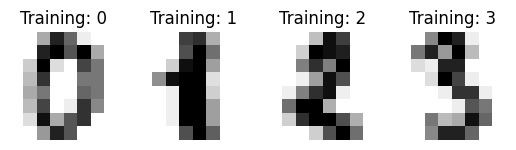

In [15]:
print("Nguyễn Khánh Hà - 6451071022")
# The data that we are interested in is made of 8x8 images of digits, let's
# have a look at the first 4 images, stored in the `images` attribute of the
# dataset.
_, axes = plt.subplots(1, 4)
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Training: %i' % label)
plt.show()

# Bước 4: Chuyển đổi mỗi ảnh – ma trận 8x8 thành vector 1x64

In [16]:
print("Nguyễn Khánh Hà - 6451071022")
# To apply a classifier on this data, we need to flatten the image, to
# turn the data in a (samples, feature) matrix:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))
print('Kích thước dữ liệu sau khi duỗi ảnh:', data.shape)

Nguyễn Khánh Hà - 6451071022
Kích thước dữ liệu sau khi duỗi ảnh: (1797, 64)


## Sử dụng thuật toán cây ID3

In [17]:
print("Nguyễn Khánh Hà - 6451071022")
# Create a classifier: a decision tree classifier
classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)

Nguyễn Khánh Hà - 6451071022


# Bước 5: Chia dữ liệu thành hai phần: huấn luyện 80%, kiểm thử 20%

In [18]:
print("Nguyễn Khánh Hà - 6451071022")
# Split data into train and test subsets
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=False)
print('Số mẫu huấn luyện:', len(X_train), '| Số mẫu kiểm thử:', len(X_test))

Nguyễn Khánh Hà - 6451071022
Số mẫu huấn luyện: 1437 | Số mẫu kiểm thử: 360


## Tiến hành xây dựng cây ID3

In [19]:
print("Nguyễn Khánh Hà - 6451071022")
# We learn the digits on the first part of the digits
classifier.fit(X_train, y_train)

Nguyễn Khánh Hà - 6451071022


DecisionTreeClassifier(criterion='entropy', random_state=33)

## Bước 6: Dự đoán nhãn dữ liệu cho tập kiểm thử

In [20]:
print("Nguyễn Khánh Hà - 6451071022")
# Now predict the value of the digit on the test part:
predicted = classifier.predict(X_test)

Nguyễn Khánh Hà - 6451071022


# Bước 7: Biểu diễn một vài kết quả dự đoán
Tập kiểm thử là 20% cuối của dữ liệu nên ảnh tương ứng được lấy từ vị trí `len(X_train)` trở đi.

Nguyễn Khánh Hà - 6451071022


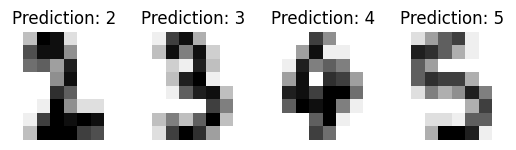

In [21]:
print("Nguyễn Khánh Hà - 6451071022")
_, axes = plt.subplots(1, 4)
images_and_predictions = list(zip(digits.images[len(X_train):], predicted))
for ax, (image, prediction) in zip(axes, images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Prediction: %i' % prediction)
plt.show()

# Bước 8: Thông số đạt được của cây ID3 và ma trận nhầm lẫn

Nguyễn Khánh Hà - 6451071022
Classification report for classifier DecisionTreeClassifier(criterion='entropy', random_state=33):
              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360


Confusion matrix:
[[31  0  0  0  1  0  0  0  1  2]
 [ 0 23  0  2  2  0  0  1  1  7]
 [ 1  2 26  0  0  1  0  3  2

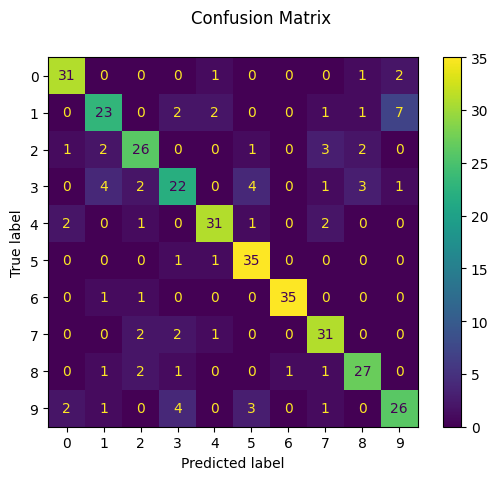

In [22]:
print("Nguyễn Khánh Hà - 6451071022")
print("Classification report for classifier %s:\n%s\n"
      % (classifier, metrics.classification_report(y_test, predicted)))
disp = metrics.ConfusionMatrixDisplay.from_estimator(classifier, X_test, y_test)
disp.figure_.suptitle("Confusion Matrix")
print("Confusion matrix:\n%s" % disp.confusion_matrix)
plt.show()

## Cài đặt thư viện xử lý hình ảnh Pillow cho Python và import vào
Trên Colab Pillow đã được cài sẵn; nếu chạy máy cá nhân thì cài bằng `pip install pillow`.

In [23]:
print("Nguyễn Khánh Hà - 6451071022")
from PIL import Image, ImageOps
import numpy as np

Nguyễn Khánh Hà - 6451071022


#Bước 9: Nhận dạng ảnh tự chụp số 1 (`test_image_Bai7_1.jpg`)
### Hiển thị ảnh gốc

Nguyễn Khánh Hà - 6451071022


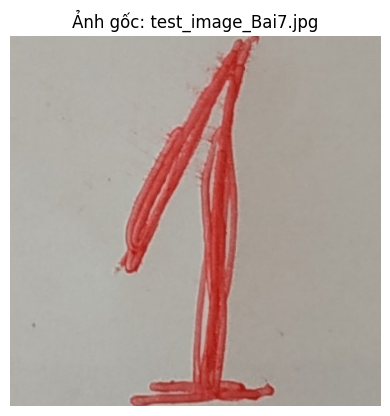

In [24]:
print("Nguyễn Khánh Hà - 6451071022")
IMG_PATH = 'test_image_Bai7.jpg'
plt.imshow(Image.open(IMG_PATH))
plt.axis('off')
plt.title('Ảnh gốc: test_image_Bai7.jpg')
plt.show()

### Đọc ảnh vào phần mềm: chuyển ảnh xám, thu nhỏ 8x8, đảo màu

Nguyễn Khánh Hà - 6451071022


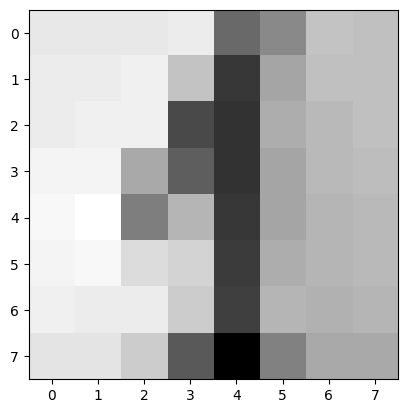

In [25]:
print("Nguyễn Khánh Hà - 6451071022")
#Open image
img = Image.open(IMG_PATH).convert("L").resize((8,8))
#Invert image
img = ImageOps.invert(img)
#Convert to numpy array
im2arr = np.array(img)
#Show
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

### Làm rõ nét bức ảnh bằng cách phân biệt rõ những giá trị đen, trắng (ngưỡng phân biệt là 110)

In [26]:
print("Nguyễn Khánh Hà - 6451071022")
#Change from 2d array (8x8) to 1d array (1x64)
img1d = im2arr.reshape([1,64])
#normalize black & white image array
img1d[img1d > 109] = 155
img1d[img1d < 110] = 0
img1d

Nguyễn Khánh Hà - 6451071022


array([[  0,   0,   0,   0, 155,   0,   0,   0,   0,   0,   0,   0, 155,
          0,   0,   0,   0,   0,   0, 155, 155,   0,   0,   0,   0,   0,
          0, 155, 155,   0,   0,   0,   0,   0,   0,   0, 155,   0,   0,
          0,   0,   0,   0,   0, 155,   0,   0,   0,   0,   0,   0,   0,
        155,   0,   0,   0,   0,   0,   0, 155, 155,   0,   0,   0]],
      dtype=uint8)

### Hình ảnh chữ số sau khi làm rõ

Nguyễn Khánh Hà - 6451071022


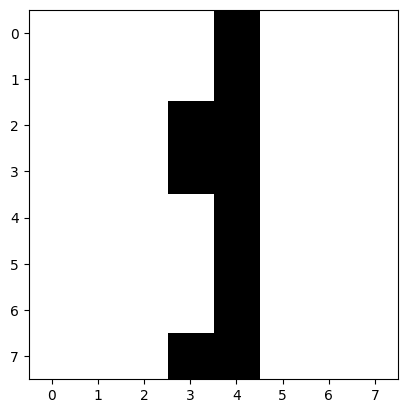

In [27]:
print("Nguyễn Khánh Hà - 6451071022")
#After normalize
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

### Tiến hành nhận diện bằng cây ID3 và in ra kết quả

In [28]:
print("Nguyễn Khánh Hà - 6451071022")
#Predict label of number
y_pred = classifier.predict(img1d)
print(y_pred)
print("Số thực tế: 1 | Cây ID3 dự đoán:", y_pred[0])

Nguyễn Khánh Hà - 6451071022
[1]
Số thực tế: 1 | Cây ID3 dự đoán: 1


#Bước 10: Nhận dạng ảnh tự chụp số 2 (`test_image_Bai7_2.jpg`)
### Hiển thị ảnh gốc

Nguyễn Khánh Hà - 6451071022


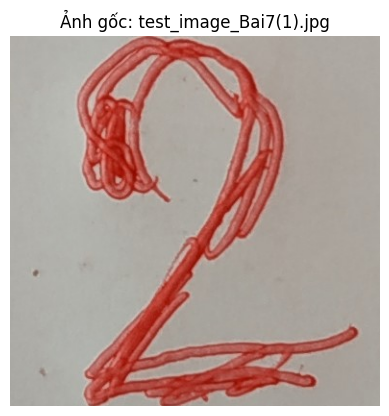

In [29]:
print("Nguyễn Khánh Hà - 6451071022")
IMG_PATH = 'test_image_Bai7(1).jpg'
plt.imshow(Image.open(IMG_PATH))
plt.axis('off')
plt.title('Ảnh gốc: test_image_Bai7(1).jpg')
plt.show()

### Đọc ảnh vào phần mềm: chuyển ảnh xám, thu nhỏ 8x8, đảo màu

Nguyễn Khánh Hà - 6451071022


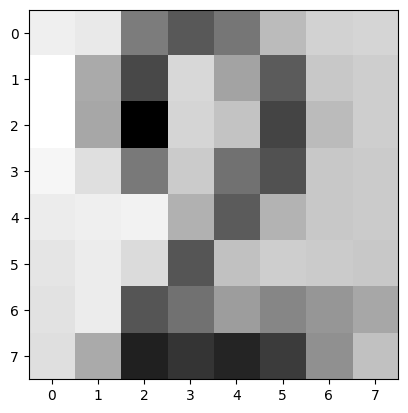

In [30]:
print("Nguyễn Khánh Hà - 6451071022")
#Open image
img = Image.open(IMG_PATH).convert("L").resize((8,8))
#Invert image
img = ImageOps.invert(img)
#Convert to numpy array
im2arr = np.array(img)
#Show
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')
plt.show()

### Làm rõ nét bức ảnh bằng cách phân biệt rõ những giá trị đen, trắng (ngưỡng phân biệt là 110)

In [31]:
print("Nguyễn Khánh Hà - 6451071022")
#Change from 2d array (8x8) to 1d array (1x64)
img1d = im2arr.reshape([1,64])
#normalize black & white image array
img1d[img1d > 109] = 155
img1d[img1d < 110] = 0
img1d

Nguyễn Khánh Hà - 6451071022


array([[  0,   0, 155, 155, 155,   0,   0,   0,   0,   0, 155,   0,   0,
        155,   0,   0,   0,   0, 155,   0,   0, 155,   0,   0,   0,   0,
        155,   0, 155, 155,   0,   0,   0,   0,   0,   0, 155,   0,   0,
          0,   0,   0,   0, 155,   0,   0,   0,   0,   0,   0, 155, 155,
          0, 155,   0,   0,   0,   0, 155, 155, 155, 155,   0,   0]],
      dtype=uint8)

### Hình ảnh chữ số sau khi làm rõ

Nguyễn Khánh Hà - 6451071022


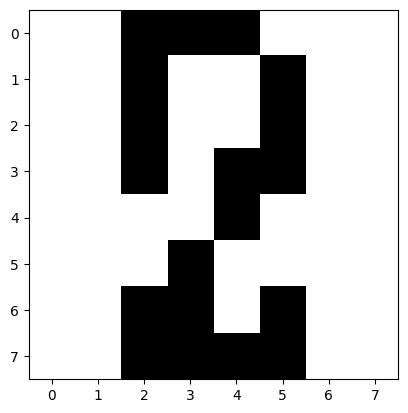

In [32]:
  print("Nguyễn Khánh Hà - 6451071022")
  #After normalize
  plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')
  plt.show()

### Tiến hành nhận diện bằng cây ID3 và in ra kết quả

In [33]:
print("Nguyễn Khánh Hà - 6451071022")
#Predict label of number
y_pred = classifier.predict(img1d)
print(y_pred)
print("Số thực tế: 2 | Cây ID3 dự đoán:", y_pred[0])

Nguyễn Khánh Hà - 6451071022
[2]
Số thực tế: 2 | Cây ID3 dự đoán: 2
